<a href="https://colab.research.google.com/github/minhphu12-oc/gg-colab/blob/early-stopping/early_stopping.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Early Stopping là kỹ thuật dừng quá trình training khi model không còn cải thiện trên tập validation, nhằm hạn chế overfitting và tránh lãng phí thời gian huấn luyện.

thực hành với thư viện Breast Cancer Wisconsin của sklearn

In [81]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import numpy as np
import pandas as pd

torch.manual_seed(42)
np.random.seed(42)

# load thư viện
data = load_breast_cancer()
x = data.data
y = data.target

# biến thành dataframe để xem dữ liệu, trạng thái
df = pd.DataFrame(x, columns=data.feature_names)
df['target'] = y

In [82]:
# xem thử dữ liệu
print(df.head(5).to_string())

   mean radius  mean texture  mean perimeter  mean area  mean smoothness  mean compactness  mean concavity  mean concave points  mean symmetry  mean fractal dimension  radius error  texture error  perimeter error  area error  smoothness error  compactness error  concavity error  concave points error  symmetry error  fractal dimension error  worst radius  worst texture  worst perimeter  worst area  worst smoothness  worst compactness  worst concavity  worst concave points  worst symmetry  worst fractal dimension  target
0        17.99         10.38          122.80     1001.0          0.11840           0.27760          0.3001              0.14710         0.2419                 0.07871        1.0950         0.9053            8.589      153.40          0.006399            0.04904          0.05373               0.01587         0.03003                 0.006193         25.38          17.33           184.60      2019.0            0.1622             0.6656           0.7119                0.2654

In [83]:
# xem thuộc tính
print(df.info())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

tất cả đầu là số và hầu hết ở dạng float ngoại trừ target nên khi chuyển về dạng tensor thì tất cả sẽ có dạng float32 còn target là long

không có dữ liệu nào bị thiếu nên không cần phải lấp missing data

target ở đây là dự đoán 0-1 là có hoặc không nên đây là dạng classification

In [84]:
print(x.shape)
print(y.shape)

(569, 30)
(569,)


In [85]:
# chia data train test
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)
# chia data train val để early stopping
x_train, x_val, y_train, y_val = train_test_split(x_train, y_train, test_size=0.2, random_state=42)
# chuẩn hoá dữ liệu
scaler = StandardScaler()
x_train = scaler.fit_transform(x_train)
x_val = scaler.transform(x_val)
x_test = scaler.transform(x_test)
# chuyển về tensor
x_train = torch.tensor(x_train, dtype=torch.float32)
x_val = torch.tensor(x_val, dtype=torch.float32)
x_test = torch.tensor(x_test, dtype=torch.float32)
y_train = torch.tensor(y_train, dtype=torch.long)
y_val = torch.tensor(y_val, dtype=torch.long)
y_test = torch.tensor(y_test, dtype=torch.long)
# chuyển về dataset
train_dataset = TensorDataset(x_train, y_train)
val_dataset = TensorDataset(x_val, y_val)
test_dataset = TensorDataset(x_test, y_test)
# chuyển về dataloader
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

hoàn thiện xong bước xử lí dữ liệu rồi thì đến xây dựng model

In [86]:
class DNN(nn.Module):
  def __init__(self, input, hidden1, hidden2, hidden3, output):
    super().__init__()
    self.linear1 = nn.Linear(input, hidden1)
    self.relu1 = nn.ReLU()
    self.dropou1 = nn.Dropout(0.2)

    self.linear2 = nn.Linear(hidden1, hidden2)
    self.relu2 = nn.ReLU()
    self.dropou2 = nn.Dropout(0.2)

    self.linear3 = nn.Linear(hidden2, hidden3)
    self.relu3 = nn.ReLU()
    self.dropou3 = nn.Dropout(0.2)

    self.linear4 = nn.Linear(hidden3, output)
    self.sigmoid = nn.Sigmoid()
  def forward(self, x):
    x = self.linear1(x)
    x = self.relu1(x)
    x = self.dropou1(x)

    x = self.linear2(x)
    x = self.relu2(x)
    x = self.dropou2(x)

    x = self.linear3(x)
    x = self.relu3(x)
    x = self.dropou3(x)

    x = self.linear4(x)
    x = self.sigmoid(x)
    return x

In [87]:
model = DNN(30, 128, 64, 32, 1)
loss_fn = nn.BCEWithLogitsLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=0.001)
patience = 15
min_delta = 0.002
patience_counter = 0
best_score = float("inf")
train_losses = []
val_losses = []
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

# train model
for epoch in range(1000):
  total_train_loss = 0
  for x_batch, y_batch in train_loader:
    model.train()
    optimizer.zero_grad()
    x_batch = x_batch.to(device)
    y_batch = y_batch.to(device)
    y_pred = model(x_batch)
    loss = loss_fn(y_pred, y_batch.unsqueeze(1).float())
    loss.backward()
    optimizer.step()
    total_train_loss += loss.item() * len(x_batch)
  epoch_train_loss = total_train_loss / len(train_loader.dataset)
  train_losses.append(epoch_train_loss)

  # early stopping
  total_val_loss = 0
  model.eval()
  with torch.no_grad():
    for x_batch, y_batch in val_loader:
      x_batch = x_batch.to(device)
      y_batch = y_batch.to(device)
      y_pred = model(x_batch)
      loss = loss_fn(y_pred, y_batch.unsqueeze(1).float())
      total_val_loss += loss.item() * len(x_batch)
  epoch_val_loss = total_val_loss / len(val_loader.dataset)
  val_losses.append(epoch_val_loss)

  if epoch_val_loss < (best_score - min_delta):
    best_score = epoch_val_loss
    patience_counter = 0
  else:
    patience_counter += 1
    if patience_counter >= patience:
      print("Early stopping!")
      print(f"Epoch: {epoch} | train loss: {epoch_train_loss:.4f} | val loss: {epoch_val_loss:.4f}")
      break

Early stopping!
Epoch: 32 | train loss: 0.4540 | val loss: 0.4814


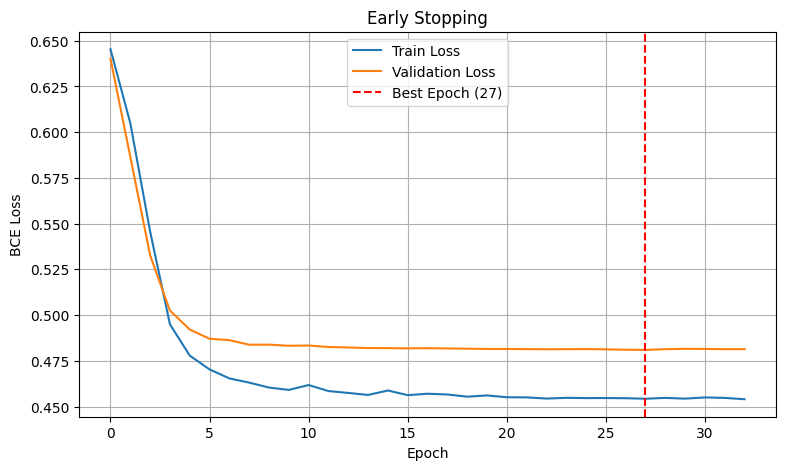

In [88]:
# vẽ biểu đồ phác hoạ
import matplotlib.pyplot as plt
best_epoch = val_losses.index(min(val_losses))
plt.figure(figsize=(9, 5))
plt.plot(train_losses, label="Train Loss")
plt.plot(val_losses, label="Validation Loss")
plt.axvline(
    best_epoch,
    color="red",
    linestyle="--",
    label=f"Best Epoch ({best_epoch})"
)
plt.xlabel("Epoch")
plt.ylabel("BCE Loss")
plt.title("Early Stopping")
plt.legend()
plt.grid()
plt.show()

In [89]:
# cho dự đoán x_test
model.eval()
with torch.no_grad():
  for x_batch, y_batch in test_loader:
    x_batch = x_batch.to(device)
    y_batch = y_batch.to(device)
    y_pred = model(x_batch)
    y_pred = (y_pred > 0.5).float()
    print("y_pred :",y_pred.reshape(1, -1))
    print("y_real :",y_batch.reshape(1, -1))

y_pred : tensor([[1., 0., 0., 1., 1., 0., 0., 0., 0., 1., 1., 0., 1., 0., 1., 0., 1., 1.,
         1., 0., 1., 1., 0., 1., 1., 1., 1., 1., 1., 0., 1., 1.]])
y_real : tensor([[1, 0, 0, 1, 1, 0, 0, 0, 1, 1, 1, 0, 1, 0, 1, 0, 1, 1, 1, 0, 0, 1, 0, 1,
         1, 1, 1, 1, 1, 0, 1, 1]])
y_pred : tensor([[1., 1., 1., 1., 0., 1., 0., 1., 1., 0., 1., 1., 1., 1., 1., 1., 1., 1.,
         0., 0., 1., 1., 1., 1., 1., 0., 0., 1., 1., 0., 0., 1.]])
y_real : tensor([[1, 1, 1, 1, 0, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1,
         1, 0, 0, 1, 1, 0, 0, 1]])
y_pred : tensor([[1., 1., 0., 0., 1., 1., 0., 0., 1., 0., 1., 1., 1., 0., 1., 1., 0., 1.,
         0., 0., 0., 0., 0., 0., 1., 1., 1., 0., 1., 1., 1., 1.]])
y_real : tensor([[1, 1, 0, 0, 1, 1, 0, 0, 1, 0, 1, 1, 1, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0,
         1, 1, 1, 1, 1, 1, 1, 1]])
y_pred : tensor([[0., 0., 1., 0., 0., 1., 0., 0., 1., 1., 1., 0., 1., 1., 0., 1., 1., 0.]])
y_real : tensor([[0, 0, 1, 0, 0, 1, 0, 0, 1, 1, 1, 0, 1, 1, 0,

In [90]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
accuracy = accuracy_score(y_batch, y_pred)
precision = precision_score(y_batch, y_pred)
recall = recall_score(y_batch, y_pred)
f1 = f1_score(y_batch, y_pred)
roc_auc = roc_auc_score(y_batch, y_pred)
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1 Score: {f1:.4f}")

Accuracy: 1.0000
Precision: 1.0000
Recall: 1.0000
F1 Score: 1.0000
